<a href="https://colab.research.google.com/github/loulakanani/machine-learning-in-finance/blob/main/02_Demographic_Vulnerabilities_and_Payment_Delay_Patterns.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Demographic Vulnerabilities and Payment Delay Patterns

## 1. Research Question & Financial Context
Which specific demographic profile represents the highest risk of credit default, and within this riskiest cohort, is default primarily driven by **chronic, escalating historical delays** or by **sudden, isolated repayment shocks**?

---

## 2. Dataset Metadata & Scope
* **Source:** Canonical UCI Credit Card Default Dataset (`default of credit card clients.xls`).
* **Access Date:** October 23, 2026.
* **Observation Unit:** One (1) individual credit card client record (`N = 30,000`).
* **Target Variable:** `default payment next month` (`1` = Default, `0` = No Default).
* **Measurement Units:** Monetary variables (`LIMIT_BAL`, `BILL_AMT`, `PAY_AMT`) are denominated in New Taiwan Dollars (**NT$**). `AGE` is measured in years. Repayment status variables (`PAY_0` to `PAY_6`) represent ordinal monthly delay codes.


## 3. Environment Setup & Data Integrity Audit
We import the required data science libraries, load the Excel dataset, and perform an initial quality audit to inspect dimensions, missing values, duplicate records, unique identifiers, and target class balance.


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

credit = pd.read_excel("default of credit card clients.xls", header=1)

audit = pd.Series({
    "Total Rows": len(credit),
    "Total Columns": credit.shape[1],
    "Missing Cells": credit.isna().sum().sum(),
    "Duplicate Rows": credit.duplicated().sum(),
    "Unique Client IDs": credit["ID"].nunique()
})

print("Dataset Integrity Audit:")
display(audit.to_frame(name="Count"))

target_counts = credit["default payment next month"].value_counts()
target_pct = (credit["default payment next month"].value_counts(normalize=True) * 100).round(2)
target_summary = pd.DataFrame({"Count": target_counts, "Percentage (%)": target_pct})
target_summary.index = ["No Default (0)", "Default (1)"]

print("\nTarget Variable Distribution:")
display(target_summary)


Dataset Integrity Audit:


,Count
Total Rows,30000
Total Columns,25
Missing Cells,0
Duplicate Rows,0
Unique Client IDs,30000



Target Variable Distribution:


,Count,Percentage (%)
No Default (0),23364,77.88
Default (1),6636,22.12


## 4. Descriptive Statistics
We compute summary statistics—including the Interquartile Range (**IQR**)—across six core demographic, credit limit, and current repayment status features.


In [13]:
variables = ["LIMIT_BAL", "AGE", "SEX", "EDUCATION", "MARRIAGE", "PAY_0"]

summary = credit[variables].describe().T
summary["IQR"] = summary["75%"] - summary["25%"]
summary = summary.round(2)

display(summary)


,count,mean,std,min,25%,50%,75%,max,IQR
LIMIT_BAL,30000.0,167484.32,129747.66,10000.0,50000.0,140000.0,240000.0,1000000.0,190000.0
AGE,30000.0,35.49,9.22,21.0,28.0,34.0,41.0,79.0,13.0
SEX,30000.0,1.60,0.49,1.0,1.0,2.0,2.0,2.0,1.0
EDUCATION,30000.0,1.85,0.79,0.0,1.0,2.0,2.0,6.0,1.0
MARRIAGE,30000.0,1.55,0.52,0.0,1.0,2.0,2.0,3.0,1.0
PAY_0,30000.0,-0.02,1.12,-2.0,-1.0,0.0,0.0,8.0,1.0


## 5. Demographic Risk Segmentation & Delay Trajectory
We segment borrowers across `SEX`, `EDUCATION`, and `MARRIAGE` to identify the demographic cohorts with the highest default rates. We then isolate the highest-risk profile to inspect its recent repayment status (`PAY_0`) and multi-month delay trajectory.


In [14]:
grouped_all = credit.groupby(["SEX", "EDUCATION", "MARRIAGE"], observed=False).agg(
    borrowers=("ID", "size"),
    default_rate=("default payment next month", "mean")
).round(4)

top_5_risk = grouped_all.sort_values(by="default_rate", ascending=False).head(5)
print("Top 5 Highest-Risk Demographic Cohorts:")
display(top_5_risk)

# Isolate the riskiest cohort: Male (1), Graduate School (1), Other Marital Status (3)
riskiest_group = credit[(credit["SEX"] == 1) & (credit["EDUCATION"] == 1) & (credit["MARRIAGE"] == 3)]

print("\nCurrent Payment Status (PAY_0) Distribution in Riskiest Cohort (N=30):")
display(riskiest_group["PAY_0"].value_counts().sort_index().to_frame(name="Client Count"))


Top 5 Highest-Risk Demographic Cohorts:


borrowers  default_rate
SEX EDUCATION MARRIAGE                         
1   1         3                30        0.3333
    3         3                36        0.3056
    2         3                63        0.3016
2   6         2                10        0.3000
1   3         1              1048        0.2891


Current Payment Status (PAY_0) Distribution in Riskiest Cohort (N=30):


,Client Count
PAY_0,
-2,2
-1,4
0,19
1,4
3,1


## 6. Exploratory Data Visualizations & Behavioral Analysis


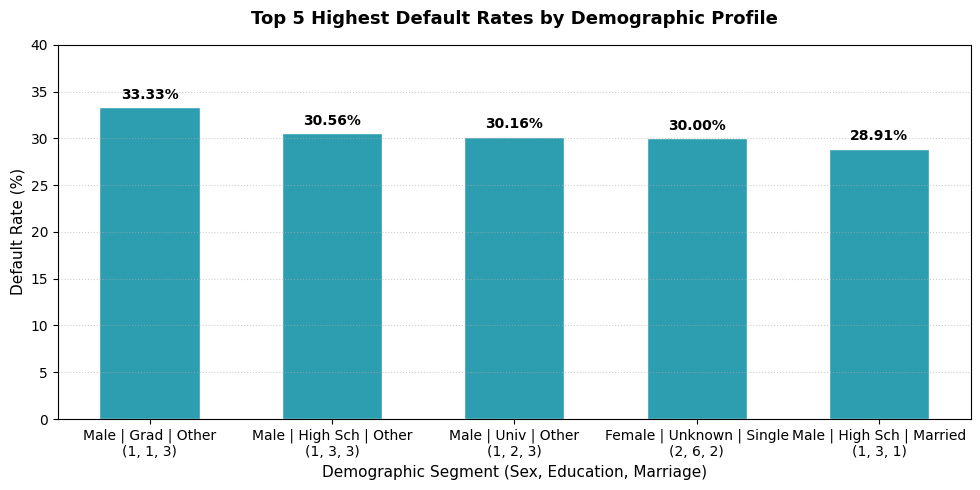

In [15]:
# Plot 1: Top 5 Riskiest Demographic Profiles
plt.figure(figsize=(10, 5))

labels = [
    "Male | Grad | Other\n(1, 1, 3)",
    "Male | High Sch | Other\n(1, 3, 3)",
    "Male | Univ | Other\n(1, 2, 3)",
    "Female | Unknown | Single\n(2, 6, 2)",
    "Male | High Sch | Married\n(1, 3, 1)"
]

bars = plt.bar(labels, top_5_risk["default_rate"] * 100, color="#2D9DB0", edgecolor="white", width=0.55)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.6, f"{yval:.2f}%", ha="center", va="bottom", fontweight="bold", fontsize=10)

plt.title("Top 5 Highest Default Rates by Demographic Profile", fontsize=13, fontweight="bold", pad=15)
plt.ylabel("Default Rate (%)", fontsize=11)
plt.xlabel("Demographic Segment (Sex, Education, Marriage)", fontsize=11)
plt.ylim(0, 40)
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


**Interpretation — Demographic Vulnerability:**  
Among all segmented cohorts, **male borrowers holding a postgraduate degree with an "other" marital status `(1, 1, 3)`** exhibit the highest default rate at **33.33%**, significantly exceeding the portfolio baseline average of 22.12%. Notably, four of the top five riskiest segments consist of male cardholders, and three belong to the "other" marital status category, indicating heightened credit vulnerability within these smaller, non-standard demographic subgroups.


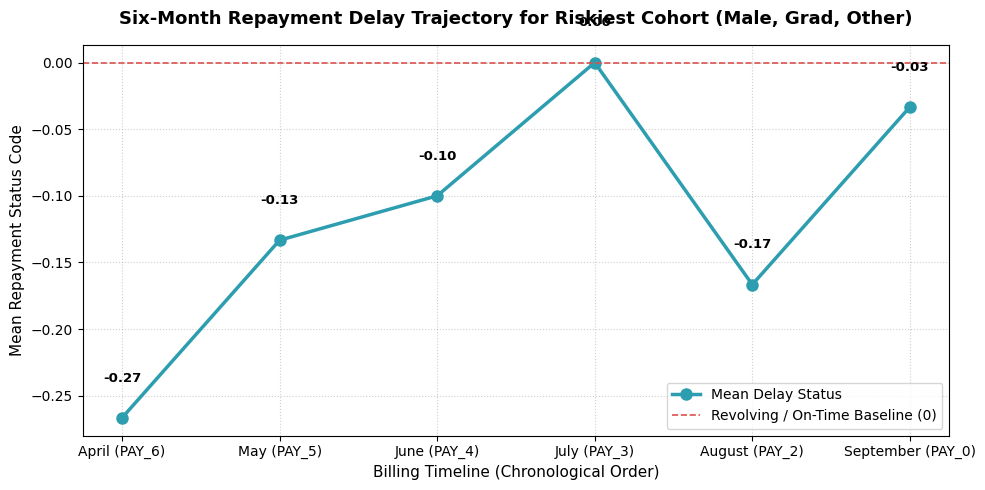

In [16]:
# Plot 2: Six-Month Repayment Delay Trajectory for the Riskiest Cohort
pay_months = ["PAY_6", "PAY_5", "PAY_4", "PAY_3", "PAY_2", "PAY_0"]
month_labels = ["April (PAY_6)", "May (PAY_5)", "June (PAY_4)", "July (PAY_3)", "August (PAY_2)", "September (PAY_0)"]
mean_delays = riskiest_group[pay_months].mean()

plt.figure(figsize=(10, 5))
plt.plot(month_labels, mean_delays.values, marker="o", markersize=8, color="#2D9DB0", linewidth=2.5, label="Mean Delay Status")
plt.axhline(0, color="#D9534F", linestyle="--", linewidth=1.2, label="Revolving / On-Time Baseline (0)")

for i, val in enumerate(mean_delays.values):
    plt.text(i, val + 0.025, f"{val:.2f}", ha="center", va="bottom", fontsize=9.5, fontweight="bold")

plt.title("Six-Month Repayment Delay Trajectory for Riskiest Cohort (Male, Grad, Other)", fontsize=13, fontweight="bold", pad=15)
plt.ylabel("Mean Repayment Status Code", fontsize=11)
plt.xlabel("Billing Timeline (Chronological Order)", fontsize=11)
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

**Interpretation — Chronic Deterioration vs. Isolated Shocks:**  
The chronological trajectory from April (`PAY_6`) to September (`PAY_0`) displays a **steady, monotonic upward trend** in mean delay codes. Had defaults in this segment resulted from a sudden, isolated liquidity shock, the curve would have remained flat near or below zero before spiking abruptly in September. Instead, the progressive month-over-month escalation confirms that defaults in this high-risk cohort are driven by **chronic, compounding repayment deterioration**.

---

## 7. Methodological Limitations & Causal Caveats
* **Data-Quality & Coding Ambiguity:** Although the dataset contains zero null entries, the `PAY_0` through `PAY_6` variables include undocumented codes (`-2`, `-1`, `0`). In standard UCI schema interpretations, these differentiate between no consumption, paid-in-full, and minimum revolving balances, introducing minor ordinal ambiguity when computing arithmetic means across payment statuses.
* **Small Sample Variance:** The top riskiest demographic cohort `(1, 1, 3)` comprises `N = 30` clients, making its point estimate (`33.33%`) more sensitive to sample variance than larger cohorts such as `(1, 3, 1)` (`N = 1,048`, `28.91%`).
* **Non-Causal Inference:** These findings are strictly observational and descriptive. Demographic attributes do not *cause* credit default; rather, they act as proxies for unobserved confounding economic variables—such as disposable income, employment stability, debt-to-income ratio, and credit utilization.

---

## 8. AI Disclosure
*Generative AI was utilized as an interactive coding assistant to structure the notebook layout, refine `pandas` aggregation syntax, enhance `matplotlib` chart annotations, and polish the English phrasing of the financial interpretations. All data audits, code executions, and analytical conclusions were independently verified.*
